In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.ticker import MultipleLocator
from scipy.stats import fisher_exact

In [2]:
plt.rcParams['svg.fonttype'] = 'none'

**1. Spermatheca + FRT (detailed)**

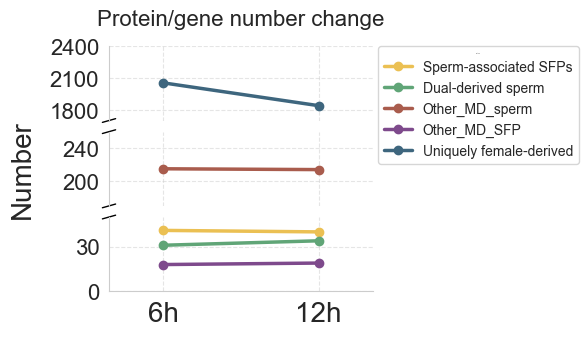

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# 1. 数据准备
time_points = ['6h', '12h']
Sperm_associated_SFPs = [41, 40]
Dual_derived_sperm = [31, 34]
Other_MD_sperm = [215, 214]
Other_MD_SFP = [18, 19]
Uniquely_female_derived = [2055, 1840]

# 2. 创建三层子图 (Top: 2000级, Mid: 200级, Bot: 50级)
fig, (ax_top, ax_mid, ax_bot) = plt.subplots(3, 1, sharex=True, figsize=(5.5, 3.5),
                                             gridspec_kw={'height_ratios': [1, 1, 1]})

# 调整整体布局
plt.subplots_adjust(hspace=0.15, left=0.22, right=0.7, top=0.85, bottom=0.15)

# 3. 循环绘图
for ax in [ax_top, ax_mid, ax_bot]:
    ax.plot(time_points, Sperm_associated_SFPs, marker='o', color='#EBC053', linewidth=2.5, label='Sperm-associated SFPs')
    ax.plot(time_points, Dual_derived_sperm, marker='o', color='#60A577', linewidth=2.5, label='Dual-derived sperm')
    ax.plot(time_points, Other_MD_sperm, marker='o', color='#A95C4D', linewidth=2.5, label='Other_MD_sperm')
    ax.plot(time_points, Other_MD_SFP, marker='o', color='#7E4A8C', linewidth=2.5, label='Other_MD_SFP')
    ax.plot(time_points, Uniquely_female_derived, marker='o', color='#3E667E', linewidth=2.5, label='Uniquely female-derived')

# 4. 设置各层级显示范围 (根据你的数值精确调整)
ax_top.set_ylim(1700, 2400) # 展示 2055, 1840
ax_mid.set_ylim(170, 260)   # 展示 215, 214
ax_bot.set_ylim(0, 50)      # 展示 18, 19, 31, 34, 40, 41

# 5. 隐藏多余边框
for ax in [ax_top, ax_mid, ax_bot]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

ax_top.spines['bottom'].set_visible(False)
ax_mid.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)

# 6. 设置标题和字体 (严格遵循原要求)
ax_top.set_title('Protein/gene number change', fontsize=16, pad=15)
fig.text(0.04, 0.5, 'Number', va='center', rotation='vertical', fontsize=20)

plt.xticks(fontsize=20)
ax_top.tick_params(axis='y', labelsize=16)
ax_mid.tick_params(axis='y', labelsize=16)
ax_bot.tick_params(axis='y', labelsize=16)

# 7. 刻度定位器 (间隔调整)
ax_top.yaxis.set_major_locator(MultipleLocator(300))
ax_mid.yaxis.set_major_locator(MultipleLocator(40))
ax_bot.yaxis.set_major_locator(MultipleLocator(30))

# 8. 绘制双分隔线（四个位置的斜杠）
d = .025
# Top 轴底部的斜杠
kwargs = dict(transform=ax_top.transAxes, color='black', clip_on=False, lw=1)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
# Mid 轴顶端和底部的斜杠
kwargs.update(transform=ax_mid.transAxes)
ax_mid.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_mid.plot((-d, +d), (-d, +d), **kwargs)
# Bot 轴顶端的斜杠
kwargs.update(transform=ax_bot.transAxes)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)

# 9. 图例、网格和横轴冗余
ax_top.legend(title='Metrics', fontsize=10, title_fontsize=0,
              bbox_to_anchor=(1.02, 1), loc='upper left',
              borderaxespad=0.0, frameon=True)

for ax in [ax_top, ax_mid, ax_bot]:
    ax.grid(True, linestyle='--', alpha=0.5)

xmin, xmax = ax_bot.get_xlim()
ax_bot.set_xlim(xmin - 0.3, xmax + 0.3)

#plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/2026.4 new/3.all_number_line2.svg", dpi=300, bbox_inches='tight')
plt.show()

**2. FRT (detailed)**

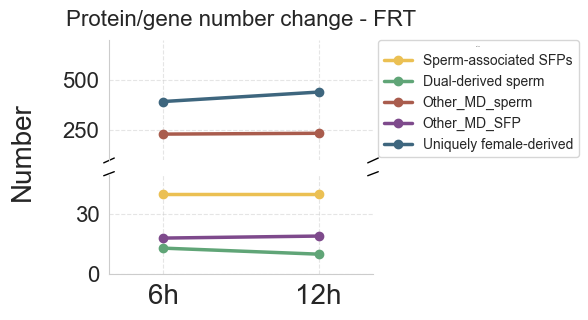

In [8]:
time_points = ['6h', '12h']
Sperm_associated_SFPs = [40, 40]
Dual_derived_sperm = [13, 10]
Other_MD_sperm = [231, 235]
Other_MD_SFP = [18, 19]
Uniquely_female_derived = [393, 440]

fig, (ax_top, ax_bot) = plt.subplots(2, 1, sharex=True, figsize=(5.5, 3.5),
                                     gridspec_kw={'height_ratios': [1.2, 1]})

plt.subplots_adjust(hspace=0.12, left=0.22, right=0.7, top=0.82, bottom=0.15)

for ax in [ax_top, ax_bot]:
    ax.plot(time_points, Sperm_associated_SFPs, marker='o', color='#EBC053', linewidth=2.5, label='Sperm-associated SFPs')
    ax.plot(time_points, Dual_derived_sperm, marker='o', color='#60A577', linewidth=2.5, label='Dual-derived sperm')
    ax.plot(time_points, Other_MD_sperm, marker='o', color='#A95C4D', linewidth=2.5, label='Other_MD_sperm')
    ax.plot(time_points, Other_MD_SFP, marker='o', color='#7E4A8C', linewidth=2.5, label='Other_MD_SFP')
    ax.plot(time_points, Uniquely_female_derived, marker='o', color='#3E667E', linewidth=2.5, label='Uniquely female-derived')

ax_top.set_ylim(100, 700)
ax_bot.set_ylim(0, 50)

ax_top.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)
ax_top.spines['right'].set_visible(False)
ax_top.spines['top'].set_visible(False)
ax_bot.spines['right'].set_visible(False)
ax_bot.spines['top'].set_visible(False)

ax_top.set_title('Protein/gene number change - FRT', fontsize=16, pad=10)

fig.text(0.04, 0.5, 'Number', va='center', rotation='vertical', fontsize=20)

plt.xticks(fontsize=20)

ax_top.tick_params(axis='y', labelsize=16)
ax_bot.tick_params(axis='y', labelsize=16)

ax_top.yaxis.set_major_locator(MultipleLocator(250))
ax_bot.yaxis.set_major_locator(MultipleLocator(30))

d = .02
kwargs = dict(transform=ax_top.transAxes, color='black', clip_on=False, lw=1)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)
kwargs.update(transform=ax_bot.transAxes)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

ax_top.legend(title='Metrics', fontsize=10, title_fontsize=0,
           bbox_to_anchor=(1.02, 1), loc='upper left',
           borderaxespad=0.0, frameon=True)

ax_top.grid(True, linestyle='--', alpha=0.5)
ax_bot.grid(True, linestyle='--', alpha=0.5)

xmin, xmax = ax_bot.get_xlim()
ax_bot.set_xlim(xmin - 0.3, xmax + 0.3)

#plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/2026.4 new/3.FRT_number_line.svg", dpi=300, bbox_inches='tight')
plt.show()

**3. Spermatheca (detailed)**

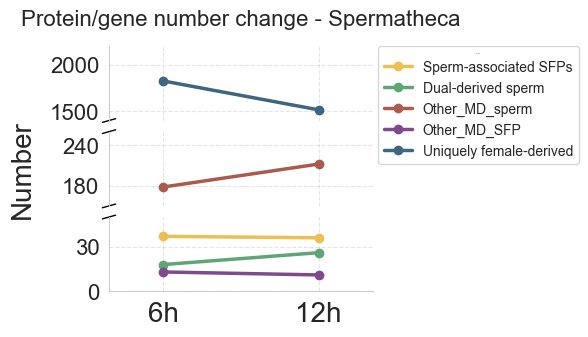

In [9]:
time_points = ['6h', '12h']
Sperm_associated_SFPs = [37, 36]
Dual_derived_sperm = [18, 26]
Other_MD_sperm = [178, 212]
Other_MD_SFP = [13, 11]
Uniquely_female_derived = [1826, 1515]

fig, (ax_top, ax_mid, ax_bot) = plt.subplots(3, 1, sharex=True, figsize=(5.5, 3.5),
                                             gridspec_kw={'height_ratios': [1, 1, 1]})

plt.subplots_adjust(hspace=0.15, left=0.22, right=0.7, top=0.85, bottom=0.15)

for ax in [ax_top, ax_mid, ax_bot]:
    ax.plot(time_points, Sperm_associated_SFPs, marker='o', color='#EBC053', linewidth=2.5, label='Sperm-associated SFPs')
    ax.plot(time_points, Dual_derived_sperm, marker='o', color='#60A577', linewidth=2.5, label='Dual-derived sperm')
    ax.plot(time_points, Other_MD_sperm, marker='o', color='#A95C4D', linewidth=2.5, label='Other_MD_sperm')
    ax.plot(time_points, Other_MD_SFP, marker='o', color='#7E4A8C', linewidth=2.5, label='Other_MD_SFP')
    ax.plot(time_points, Uniquely_female_derived, marker='o', color='#3E667E', linewidth=2.5, label='Uniquely female-derived')

ax_top.set_ylim(1400, 2200)
ax_mid.set_ylim(150, 260)
ax_bot.set_ylim(0, 50)

for ax in [ax_top, ax_mid, ax_bot]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

ax_top.spines['bottom'].set_visible(False)
ax_mid.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False) # ax_mid 的 top 已经在上面循环关掉了

ax_top.set_title('Protein/gene number change - Spermatheca', fontsize=16, pad=15)
fig.text(0.04, 0.5, 'Number', va='center', rotation='vertical', fontsize=20)

plt.xticks(fontsize=20)
ax_top.tick_params(axis='y', labelsize=16)
ax_mid.tick_params(axis='y', labelsize=16)
ax_bot.tick_params(axis='y', labelsize=16)

ax_top.yaxis.set_major_locator(MultipleLocator(500))
ax_mid.yaxis.set_major_locator(MultipleLocator(60))
ax_bot.yaxis.set_major_locator(MultipleLocator(30))

d = .025
kwargs = dict(transform=ax_top.transAxes, color='black', clip_on=False, lw=1)

ax_top.plot((-d, +d), (-d, +d), **kwargs)

kwargs.update(transform=ax_mid.transAxes)
ax_mid.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_mid.plot((-d, +d), (-d, +d), **kwargs)

kwargs.update(transform=ax_bot.transAxes)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)

ax_top.legend(title='Metrics', fontsize=10, title_fontsize=0,
              bbox_to_anchor=(1.02, 1), loc='upper left',
              borderaxespad=0.0, frameon=True)

for ax in [ax_top, ax_mid, ax_bot]:
    ax.grid(True, linestyle='--', alpha=0.5)

xmin, xmax = ax_bot.get_xlim()
ax_bot.set_xlim(xmin - 0.3, xmax + 0.3)

#plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/2026.4 new/3.Spermatheca_number_line.svg", dpi=300, bbox_inches='tight')
plt.show()

**4. Spermatheca + FRT (general)**

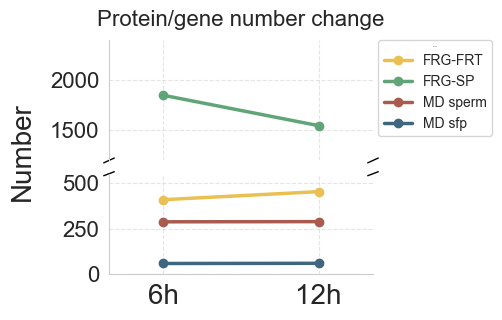

In [6]:
time_points = ['6h', '12h']  # 横坐标

FRG_FRT = [408, 452]
FRG_SP = [1848, 1546]
MDsperm = [287, 288]
MDsfp = [59, 60]

fig, (ax_top, ax_bot) = plt.subplots(2, 1, sharex=True, figsize=(5.5, 3.5),
                                     gridspec_kw={'height_ratios': [1.2, 1]})

plt.subplots_adjust(hspace=0.12, left=0.22, right=0.7, top=0.82, bottom=0.15)

for ax in [ax_top, ax_bot]:
    ax.plot(time_points, FRG_FRT, marker='o', color='#EBC053', linewidth=2.5, label='FRG-FRT')
    ax.plot(time_points, FRG_SP, marker='o', color='#60A577', linewidth=2.5, label='FRG-SP')
    ax.plot(time_points, MDsperm, marker='o', color='#A95C4D', linewidth=2.5, label='MD sperm')
    ax.plot(time_points, MDsfp, marker='o', color='#3E667E', linewidth=2.5, label='MD sfp')

ax_top.set_ylim(1200, 2400)
ax_bot.set_ylim(0, 550)

ax_top.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)
ax_top.spines['right'].set_visible(False)
ax_top.spines['top'].set_visible(False)
ax_bot.spines['right'].set_visible(False)
ax_bot.spines['top'].set_visible(False)

ax_top.set_title('Protein/gene number change', fontsize=16, pad=10)

fig.text(0.04, 0.5, 'Number', va='center', rotation='vertical', fontsize=20)

plt.xticks(fontsize=20)

ax_top.tick_params(axis='y', labelsize=16)
ax_bot.tick_params(axis='y', labelsize=16)

ax_top.yaxis.set_major_locator(MultipleLocator(500))
ax_bot.yaxis.set_major_locator(MultipleLocator(250))

d = .02
kwargs = dict(transform=ax_top.transAxes, color='black', clip_on=False, lw=1)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)
kwargs.update(transform=ax_bot.transAxes)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

ax_top.legend(title='Metrics', fontsize=10, title_fontsize=0,
           bbox_to_anchor=(1.02, 1), loc='upper left',
           borderaxespad=0.0, frameon=True)

ax_top.grid(True, linestyle='--', alpha=0.5)
ax_bot.grid(True, linestyle='--', alpha=0.5)

xmin, xmax = ax_bot.get_xlim()
ax_bot.set_xlim(xmin - 0.3, xmax + 0.3)
#plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/2026.4 new/3.all_number_line.svg", dpi=300, bbox_inches='tight')
plt.show()